<a href="https://colab.research.google.com/github/bejon23/AI-Data-Eng-Architect-Bio-Health-Operational-/blob/main/UPWORK_customization_Meta_analydis_automation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Meta-Analysis Automation Kit
**By Dr. Bejon Kumar Bhowmick | Biomedical AI & Data Engineering**

Problem
Doing a meta-analysis by hand is slow. A small mistake in pooling, heterogeneity or plots can cost a thesis chapter or a journal review round.

Solution
This notebook takes study-level data, builds the PRISMA flow, calculates effect sizes (Hedges' g), pools them with fixed and random models, checks heterogeneity and publication bias, and writes the results paragraph automatically.


Output
PRISMA diagram · Forest plot · Funnel plot · Egger's test · Leave-one-out check · Auto-written results text

*Demo uses synthetic data. Replace it with your own study table.*

Cell 1: Setup
Loads the libraries (all are already in Colab).

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
print("✅ Setup done")

✅ Setup done


Cell 2: Research question and study data
Creates 25 demo studies and calculates Hedges' g for each. To use real data, replace the dataframe with your own CSV that has the same columns.

In [2]:

PICO = {
    "Population": "Adults with type 2 diabetes",
    "Intervention": "Structured exercise program",
    "Comparison": "Usual care",
    "Outcome": "HbA1c reduction (standardized mean difference)",
}

rng = np.random.default_rng(42)
k = 25
theta = 0.45 + rng.normal(0, 0.15, k)          # true effect per study
n1 = rng.integers(20, 120, k)                  # treatment group size
n2 = rng.integers(20, 120, k)                  # control group size
sd_pool = rng.uniform(8, 14, k)
sd1 = sd_pool * rng.uniform(0.9, 1.1, k)
sd2 = sd_pool * rng.uniform(0.9, 1.1, k)
m2 = rng.normal(50, 3, k)
m1 = m2 + theta * sd_pool + rng.normal(0, sd_pool * np.sqrt(1 / n1 + 1 / n2))

df = pd.DataFrame({"study": [f"Trial {chr(65 + i)}" for i in range(k)],
                   "year": rng.integers(2008, 2024, k),
                   "n1": n1, "mean1": m1, "sd1": sd1,
                   "n2": n2, "mean2": m2, "sd2": sd2})

# df = pd.read_csv("my_studies.csv")   # use your own data with the same columns

# Hedges' g and its variance
sp = np.sqrt(((df.n1 - 1) * df.sd1**2 + (df.n2 - 1) * df.sd2**2) / (df.n1 + df.n2 - 2))
d = (df.mean1 - df.mean2) / sp
J = 1 - 3 / (4 * (df.n1 + df.n2 - 2) - 1)
df["g"] = J * d
df["var_g"] = (df.n1 + df.n2) / (df.n1 * df.n2) + df["g"] ** 2 / (2 * (df.n1 + df.n2))
df["se"] = np.sqrt(df["var_g"])
df = df.sort_values("year").reset_index(drop=True)
k = len(df)

for key, val in PICO.items():
    print(f"{key}: {val}")
print(f"\nStudies included: {k}")
df[["study", "year", "n1", "n2", "g", "se"]].round(3).head(8)

Population: Adults with type 2 diabetes
Intervention: Structured exercise program
Comparison: Usual care
Outcome: HbA1c reduction (standardized mean difference)

Studies included: 25


,study,year,n1,n2,g,se
0,Trial Q,2008,110,100,0.592,0.141
1,Trial G,2009,74,63,0.464,0.174
2,Trial X,2009,32,83,0.534,0.211
3,Trial M,2009,56,51,0.277,0.194
4,Trial E,2010,69,86,-0.107,0.162
5,Trial K,2011,112,90,0.535,0.144
6,Trial A,2012,95,67,0.656,0.164
7,Trial P,2013,52,63,0.164,0.188


Cell 3: PRISMA flow diagram
Draws the study selection flow. Change the numbers to match your search.

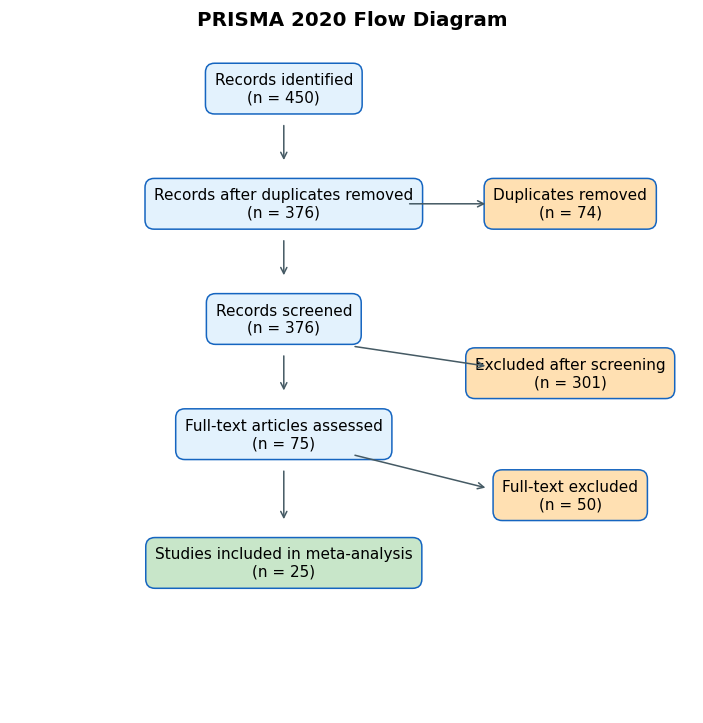

In [3]:

identified, dup_removed, full_text = 450, 74, 75
screened = identified - dup_removed
excluded_screen = screened - full_text
excluded_full = full_text - k

fig, ax = plt.subplots(figsize=(8, 8))
ax.axis("off")
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)

def box(x, y, text, color="#e3f2fd"):
    ax.text(x, y, text, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.6", fc=color, ec="#1565c0"))

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="#455a64"))

box(4, 9.2, f"Records identified\n(n = {identified})")
box(4, 7.5, f"Records after duplicates removed\n(n = {screened})")
box(4, 5.8, f"Records screened\n(n = {screened})")
box(4, 4.1, f"Full-text articles assessed\n(n = {full_text})")
box(4, 2.2, f"Studies included in meta-analysis\n(n = {k})", "#c8e6c9")
box(8.2, 7.5, f"Duplicates removed\n(n = {dup_removed})", "#ffe0b2")
box(8.2, 5.0, f"Excluded after screening\n(n = {excluded_screen})", "#ffe0b2")
box(8.2, 3.2, f"Full-text excluded\n(n = {excluded_full})", "#ffe0b2")

arrow(4, 8.7, 4, 8.1); arrow(4, 7.0, 4, 6.4); arrow(4, 5.3, 4, 4.7); arrow(4, 3.6, 4, 2.8)
arrow(5.8, 7.5, 7.0, 7.5); arrow(5.0, 5.4, 7.0, 5.1); arrow(5.0, 3.8, 7.0, 3.3)
ax.set_title("PRISMA 2020 Flow Diagram", fontsize=13, fontweight="bold")
plt.savefig("prisma_flow.png", dpi=300, bbox_inches="tight")
plt.show()

Cell 4: Pooling and heterogeneity
Calculates fixed and random effects, Q, I² and tau², then picks the model automatically.

In [4]:

def pool(y, v):
    n = len(y)
    w = 1 / v
    fe = np.sum(w * y) / np.sum(w)
    se_fe = np.sqrt(1 / np.sum(w))
    Q = np.sum(w * (y - fe) ** 2)
    dfree = n - 1
    p_Q = 1 - stats.chi2.cdf(Q, dfree)
    I2 = max(0.0, (Q - dfree) / Q) * 100 if Q > 0 else 0.0
    C = np.sum(w) - np.sum(w ** 2) / np.sum(w)
    tau2 = max(0.0, (Q - dfree) / C)
    w_re = 1 / (v + tau2)
    re = np.sum(w_re * y) / np.sum(w_re)
    se_re = np.sqrt(1 / np.sum(w_re))

    def pack(est, se):
        z = est / se
        return {"est": est, "se": se, "lo": est - 1.96 * se,
                "hi": est + 1.96 * se, "p": 2 * (1 - stats.norm.cdf(abs(z)))}

    return {"fixed": pack(fe, se_fe), "random": pack(re, se_re),
            "Q": Q, "df": dfree, "p_Q": p_Q, "I2": I2, "tau2": tau2, "w_re": w_re}

y = df["g"].values
v = df["var_g"].values
res = pool(y, v)

use_random = (res["I2"] >= 50) or (res["p_Q"] < 0.10)
model_name = "random-effects" if use_random else "fixed-effect"
final = res["random"] if use_random else res["fixed"]

table = pd.DataFrame({
    "Model": ["Fixed-effect", "Random-effects"],
    "Pooled g": [res["fixed"]["est"], res["random"]["est"]],
    "95% CI low": [res["fixed"]["lo"], res["random"]["lo"]],
    "95% CI high": [res["fixed"]["hi"], res["random"]["hi"]],
    "p-value": [res["fixed"]["p"], res["random"]["p"]],
}).round(4)
display(table)
print(f"Cochran's Q = {res['Q']:.2f} (df = {res['df']}, p = {res['p_Q']:.4f})")
print(f"I² = {res['I2']:.1f}%   tau² = {res['tau2']:.4f}")
print(f"➡ Model chosen automatically: {model_name}")

,Model,Pooled g,95% CI low,95% CI high,p-value
0,Fixed-effect,0.4465,0.3773,0.5156,0.0
1,Random-effects,0.4430,0.3551,0.5308,0.0


Cochran's Q = 37.74 (df = 24, p = 0.0369)
I² = 36.4%   tau² = 0.0179
➡ Model chosen automatically: random-effects


Cell 5: Forest plot

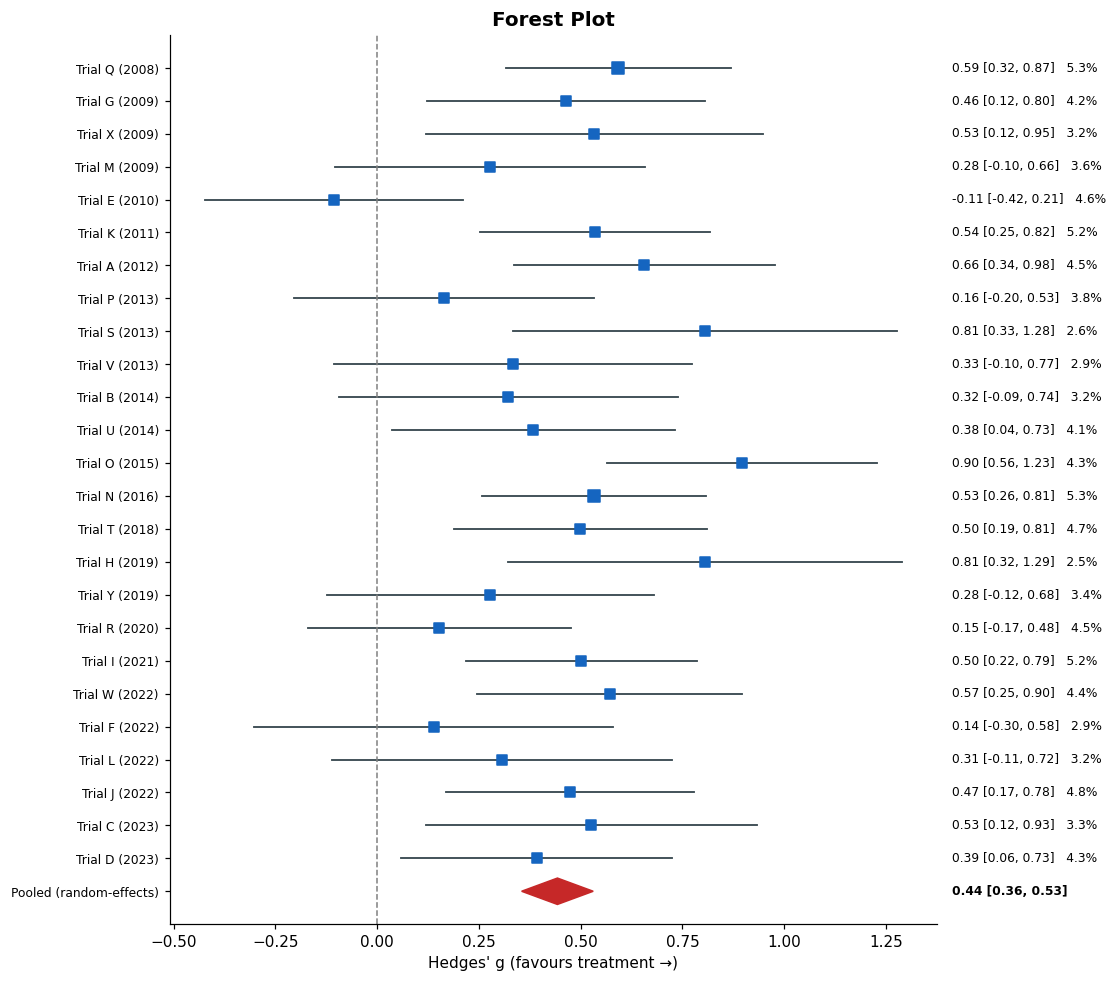

In [5]:

w_pct = 100 * res["w_re"] / res["w_re"].sum()
lo_i = y - 1.96 * df["se"].values
hi_i = y + 1.96 * df["se"].values

fig, ax = plt.subplots(figsize=(9, 0.32 * k + 2.5))
ypos = np.arange(k, 0, -1)

for i in range(k):
    ax.plot([lo_i[i], hi_i[i]], [ypos[i], ypos[i]], color="#37474f", lw=1.2)
    ax.scatter(y[i], ypos[i], marker="s", s=20 + 6 * w_pct[i], color="#1565c0", zorder=3)
    ax.text(1.02, ypos[i], f"{y[i]:.2f} [{lo_i[i]:.2f}, {hi_i[i]:.2f}]   {w_pct[i]:.1f}%",
            transform=ax.get_yaxis_transform(), va="center", fontsize=8)

ax.fill([final["lo"], final["est"], final["hi"], final["est"]],
        [0, 0.4, 0, -0.4], color="#c62828", zorder=3)
ax.text(1.02, 0, f"{final['est']:.2f} [{final['lo']:.2f}, {final['hi']:.2f}]",
        transform=ax.get_yaxis_transform(), va="center", fontsize=8, fontweight="bold")

ax.axvline(0, color="gray", ls="--", lw=1)
ax.set_yticks(list(ypos) + [0])
ax.set_yticklabels([f"{s} ({yr})" for s, yr in zip(df.study, df.year)] + [f"Pooled ({model_name})"], fontsize=8)
ax.set_ylim(-1, k + 1)
ax.set_xlabel("Hedges' g (favours treatment →)")
ax.set_title("Forest Plot", fontsize=13, fontweight="bold")
plt.savefig("forest_plot.png", dpi=300, bbox_inches="tight")
plt.show()

Cell 6: Funnel plot, Egger's test and leave-one-out
Checks publication bias and whether one study drives the result.

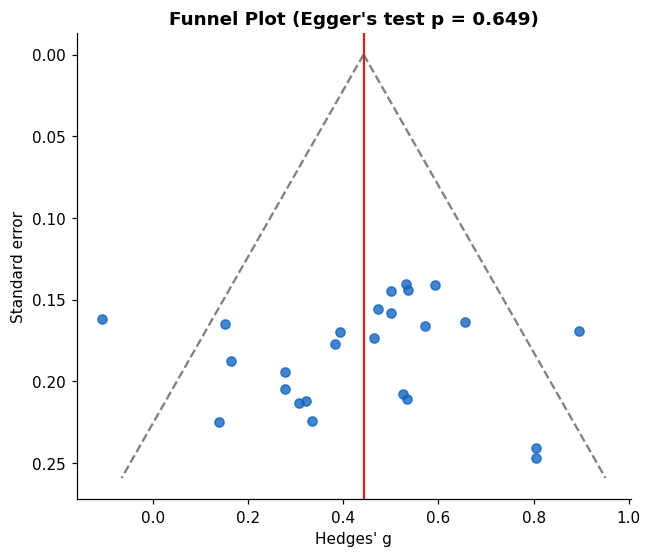

Egger's intercept = -0.722, p = 0.649
Leave-one-out pooled g ranges from 0.423 to 0.473


In [6]:

se = df["se"].values

# Egger's regression test
prec = 1 / se
snd = y / se
X = np.column_stack([np.ones(k), prec])
beta = np.linalg.lstsq(X, snd, rcond=None)[0]
resid = snd - X @ beta
sigma2 = np.sum(resid ** 2) / (k - 2)
cov = sigma2 * np.linalg.inv(X.T @ X)
se_int = np.sqrt(cov[0, 0])
t_int = beta[0] / se_int
p_egger = 2 * (1 - stats.t.cdf(abs(t_int), k - 2))

# Funnel plot
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(y, se, color="#1565c0", alpha=0.8)
grid = np.linspace(0, se.max() * 1.05, 50)
ax.plot(final["est"] - 1.96 * grid, grid, "--", color="gray")
ax.plot(final["est"] + 1.96 * grid, grid, "--", color="gray")
ax.axvline(final["est"], color="#c62828")
ax.invert_yaxis()
ax.set_xlabel("Hedges' g")
ax.set_ylabel("Standard error")
ax.set_title(f"Funnel Plot (Egger's test p = {p_egger:.3f})", fontweight="bold")
plt.savefig("funnel_plot.png", dpi=300, bbox_inches="tight")
plt.show()

# Leave-one-out sensitivity
loo = []
for i in range(k):
    mask = np.arange(k) != i
    r = pool(y[mask], v[mask])["random"]
    loo.append(r["est"])
loo = np.array(loo)
print(f"Egger's intercept = {beta[0]:.3f}, p = {p_egger:.3f}")
print(f"Leave-one-out pooled g ranges from {loo.min():.3f} to {loo.max():.3f}")

Cell 7: Auto-written results and save files

In [7]:

def pfmt(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

het_word = "low" if res["I2"] < 25 else "moderate" if res["I2"] < 50 else "substantial" if res["I2"] < 75 else "considerable"
effect_word = "a significant" if final["p"] < 0.05 else "no significant"
bias_text = ("no evidence of small-study effects" if p_egger >= 0.05
             else "possible small-study effects, so results should be read with caution")
total_n = int(df.n1.sum() + df.n2.sum())

results_text = (
    f"A total of {k} studies with {total_n} participants were included. "
    f"Using a {model_name} model, the pooled standardized mean difference (Hedges' g) was "
    f"{final['est']:.2f} (95% CI {final['lo']:.2f} to {final['hi']:.2f}; {pfmt(final['p'])}), "
    f"showing {effect_word} effect. Heterogeneity was {het_word} "
    f"(I² = {res['I2']:.1f}%, Q = {res['Q']:.2f}, {pfmt(res['p_Q'])}, tau² = {res['tau2']:.3f}). "
    f"Egger's test showed {bias_text} ({pfmt(p_egger)}). "
    f"In leave-one-out analysis, the pooled estimate stayed between {loo.min():.2f} and {loo.max():.2f}."
)

print("📝 AUTO-WRITTEN RESULTS\n")
print(results_text)

df.to_csv("meta_analysis_data.csv", index=False)
with open("results_paragraph.txt", "w") as f:
    f.write(results_text)
print("\n✅ Saved: prisma_flow.png, forest_plot.png, funnel_plot.png, meta_analysis_data.csv, results_paragraph.txt")

📝 AUTO-WRITTEN RESULTS

A total of 25 studies with 3534 participants were included. Using a random-effects model, the pooled standardized mean difference (Hedges' g) was 0.44 (95% CI 0.36 to 0.53; p < 0.001), showing a significant effect. Heterogeneity was moderate (I² = 36.4%, Q = 37.74, p = 0.037, tau² = 0.018). Egger's test showed no evidence of small-study effects (p = 0.649). In leave-one-out analysis, the pooled estimate stayed between 0.42 and 0.47.

✅ Saved: prisma_flow.png, forest_plot.png, funnel_plot.png, meta_analysis_data.csv, results_paragraph.txt
